# FG day · Чи можна за погодою заздалегідь виділити дні з пожежами?

**Тип:** виміряно. **Навіщо:** Чи дозволяють відкриті погодні дані заздалегідь виділити дні з підвищеною ймовірністю вогню.

Цей ноутбук повторює блок сторінки досліджень `web/science/#b` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('FG_day'))

T2 · Прогноз пожежного дня за погодою.

Задача      щоденна бінарна класифікація для зони парку (+3 км):
              fire_day — у цей день є хоча б одна детекція FIRMS (активна пожежа);
              ignition — у цей день починається нова подія ST-DBSCAN (нове займання).
Лейбли      NASA FIRMS (VIIRS + MODIS), фільтр впевненості; події — ST-DBSCAN (1.5 км / 2 доби).
Ознаки      NASA POWER у центрі парку: T max, RH, вітер, опади, вологість ґрунту + похідні (VPD, сухі дні поспіль,
            суми/середні 7–30 діб, індекс Нестерова), сезонність (sin/cos дня року). Усе відомо на ранок дня (без витоку).
Протокол    expanding-window forward chaining за роками: тест 2023 (навчання 2021–22), тест 2024 (2021–23), тест 2025 (2021–24).
            Гіперпараметри зафіксовані заздалегідь; оцінка — на зібраних out-of-fold прогнозах 2023–2025 + по кожному фолду.
Метрики     PR-AUC — основна: позитивів ~2–3 %, ROC-AUC на такому дисбалансі оптимістичний;
            recall@10 % — частка пожежних дні

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,val_pr_auc,pr_auc,pr_auc_ci,recall_at_10,champion
0,persistence,0.163,0.193,0.116–0.281,0.398,False
1,climatology,0.238,0.159,0.103–0.228,0.340,False
2,index_dry_days,0.178,0.091,0.065–0.134,0.178,False
3,index_vpd7,0.087,0.050,0.037–0.074,0.079,False
4,index_nesterov,0.148,0.062,0.047–0.085,0.073,False
5,index_fwi,0.108,0.087,0.053–0.140,0.099,False
6,logreg_weather,0.231,0.170,0.125–0.231,0.382,False
7,logreg_weather_season,0.177,0.188,0.137–0.254,0.403,False
8,logreg_weather_season_unweighted,0.197,0.205,0.151–0.277,0.435,False
9,random_forest,0.316,0.297,0.185–0.394,0.387,False


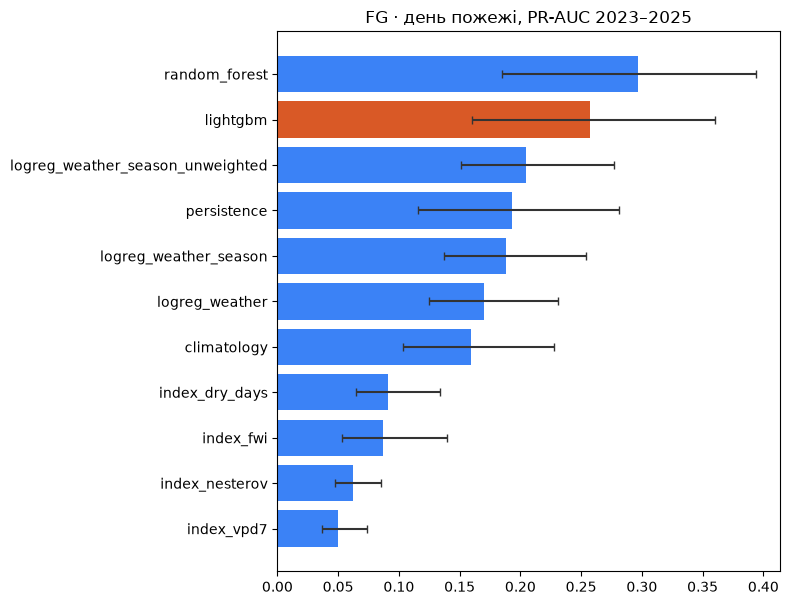

In [3]:
table, fig = report.show('FG_day')
table